In [1]:
import numpy as np
import re
import math
import sys
from collections import defaultdict, Counter
import json
import itertools
import warnings
import statistics
from pathlib import Path
import zipfile
from scipy import interpolate
from matplotlib import pyplot as plt
%matplotlib inline

In [2]:
def notebook_path_on_disk():
    return Path(json.loads(Path(sys.argv[-1]).read_bytes())['jupyter_session'])

modification_data = {
    'short_across_traces': [31, 32, 33, 34, 35, 41, 42, 43, 44, 45],
    'short_within_trace': [26, 27, 28, 29, 30, 46, 47, 48, 49, 50],
    'open': [21, 22, 23, 24, 25, 36, 37, 38, 39, 40],
    'probe_points': [53, 54, 55],
}

def load_multichannel_data(path=None):
    if path is None:
        # Get the data dir independent on where exactly the Jupyter server is running
        path = notebook_path_on_disk().parent.parent / 'data_multi'
        
    data_dict = defaultdict(list)
    for le_zip in path.glob('*.zip'):
        le_zip = zipfile.ZipFile(le_zip)
        for entry in le_zip.infolist():
            if not entry.filename.endswith('.json'):
                continue
            data = json.loads(le_zip.read(entry))
            info = data['info']
            meta, specimen = info['meta'], info['specimen']
            mesh_id = specimen
            _rest, _, serial = specimen.rpartition('-')
            try:
                serial = int(serial)
            except:
                serial = 'none'

            mods = []
            for modification, matching_serials in modification_data.items():
                if serial in matching_serials:
                    mods.append(modification)
            info['mods'] = mods

            if (g := re.search(r'p([.0-9]+)', meta)):
                pitch = str(float(*g.groups()))
            else:
                warnings.warn(f'Unknown pitch for {meta!r}')
                pitch = '?'

            mesh_layout = re.sub(r'-\d{4}', '', specimen)
            
            if (g := re.search(r'side-([ab])-(right|left)', meta)):
                layer, half = g.groups()
                mesh_id = f'M-{specimen}-{pitch}-{layer}-{half}'
                mesh_layout += f'-{layer}-{half}'
            else:
                mesh_id = f'M-{specimen}-{pitch}'
            info['mesh_id'] = mesh_id
            info['mesh_layout'] = mesh_layout
            info['pitch'] = pitch
            info['serial'] = serial if serial != 'none' else 0
            data_dict[mesh_id].append(data)
    return data_dict

data = load_multichannel_data()

/tmp/ipykernel_114442/38662701.py:41: UserWarning: Unknown pitch for 'cal-open'
  warnings.warn(f'Unknown pitch for {meta!r}')
/tmp/ipykernel_114442/38662701.py:41: UserWarning: Unknown pitch for 'baseline-5-open'
  warnings.warn(f'Unknown pitch for {meta!r}')


In [3]:
{key: value[0]['info'].get('mods') for key, value in data.items()}

{'M-none-?': [],
 'M-SP-PITCH-V2-0028-0.3': ['short_within_trace'],
 'M-SP-PITCH-V2-0030-0.3': ['short_within_trace'],
 'M-SP-PITCH-V2-0027-0.3': ['short_within_trace'],
 'M-SP-PITCH-V2-0026-0.3': ['short_within_trace'],
 'M-SP-PITCH-V2-0029-0.3': ['short_within_trace'],
 'M-SP-PITCH-V2-0010-0.3': [],
 'M-SP-PITCH-V2-0050-0.3': ['short_within_trace'],
 'M-SP-PITCH-V2-0009-0.3': [],
 'M-SP-PITCH-V2-0049-0.3': ['short_within_trace'],
 'M-SP-PITCH-V2-0008-0.3': [],
 'M-SP-PITCH-V2-0048-0.3': ['short_within_trace'],
 'M-SP-PITCH-V2-0007-0.3': [],
 'M-SP-PITCH-V2-0047-0.3': ['short_within_trace'],
 'M-SP-PITCH-V2-0006-0.3': [],
 'M-SP-PITCH-V2-0046-0.3': ['short_within_trace'],
 'M-SP-PITCH-V2-0001-0.3': [],
 'M-SP-PITCH-V2-0002-0.3': [],
 'M-SP-PITCH-V2-0003-0.3': [],
 'M-SP-PITCH-V2-0004-0.3': [],
 'M-SP-PITCH-V2-0005-0.3': [],
 'M-SP-PITCH-V2-0100-0.3': [],
 'M-SP-PITCH-V2-0097-0.3': [],
 'M-SP-PITCH-V2-0096-0.3': [],
 'M-SP-PITCH-V2-0099-0.3': [],
 'M-SP-PITCH-V2-0098-0.3': [],
 'M-SP-P

In [4]:
Counter([value['info']['meta'] for entries in data.values() for value in entries])

Counter({'Baseline-2-p0.3': 100,
         'Baseline-1-p0.3': 30,
         'Baseline-2-p0.4': 30,
         'probe-interleave-25-07-02-01-p0.4': 28,
         'probe-interleave-25-07-02-01-p0.3': 26,
         'Baseline-1-p0.4': 25,
         'touch-interleave-touch-serial-5-25-07-02-01-p0.3': 23,
         'interleaved-25-07-02-01-p0.3': 20,
         'interleaved-25-07-02-02-p0.3': 20,
         'hot-mesh-hot-serial-5-25-07-02-01-p0.3': 20,
         'touch-ground-interleave-touch-serial-5-25-07-02-01-p0.3': 20,
         'mods-25-07-01-01-p0.3': 16,
         'mods-25-07-01-01-p0.4': 16,
         'baseline-4-p0.4': 15,
         'mods-25-07-01-01-p0.6': 15,
         'mods-25-07-01-01-p1.0': 15,
         'mod-25-07-02-01-p0.3': 12,
         'baseline-repeat-25-07-02-01-p0.3': 11,
         'baseline-4-p0.3': 10,
         'baseline-repeat-25-07-02-02-p0.3': 10,
         'Baseline-2-alt-side-a-right-p0.4': 10,
         'Baseline-1-alt-side-a-right-p0.4': 10,
         'Baseline-2-alt-side-a-left-p0.

In [5]:
for foo in data.values():
    for elem in foo:
        if elem['info']['meta'] == 'hot-mesh-hot-serial-5-25-07-02-01-p0.4':
            print(elem['info'])

{'meta': 'hot-mesh-hot-serial-5-25-07-02-01-p0.4', 'specimen': 'SP-PITCH-V2-0004', 'mcu': '203632423631500f003f0034', 'chip': 'pi3hdx12211', 'timestamp': '2025-07-02T14:55:35.537Z', 'mods': [], 'mesh_id': 'M-SP-PITCH-V2-0004-0.4', 'mesh_layout': 'SP-PITCH-V2', 'pitch': '0.4', 'serial': 4}
{'meta': 'hot-mesh-hot-serial-5-25-07-02-01-p0.4', 'specimen': 'SP-PITCH-V2-0004', 'mcu': '203632423631500f003f0034', 'chip': 'pi3hdx12211', 'timestamp': '2025-07-02T14:55:42.414Z', 'mods': [], 'mesh_id': 'M-SP-PITCH-V2-0004-0.4', 'mesh_layout': 'SP-PITCH-V2', 'pitch': '0.4', 'serial': 4}
{'meta': 'hot-mesh-hot-serial-5-25-07-02-01-p0.4', 'specimen': 'SP-PITCH-V2-0004', 'mcu': '203632423631500f003f0034', 'chip': 'pi3hdx12211', 'timestamp': '2025-07-02T14:55:48.986Z', 'mods': [], 'mesh_id': 'M-SP-PITCH-V2-0004-0.4', 'mesh_layout': 'SP-PITCH-V2', 'pitch': '0.4', 'serial': 4}
{'meta': 'hot-mesh-hot-serial-5-25-07-02-01-p0.4', 'specimen': 'SP-PITCH-V2-0004', 'mcu': '203632423631500f003f0034', 'chip': 'pi3

In [6]:
[value['info'] for entries in data.values() for value in entries if value['info']['meta'] == 'mods-25-07-01-01-p0.3']

[{'meta': 'mods-25-07-01-01-p0.3',
  'specimen': 'SP-PITCH-V2-0028',
  'mcu': '203632423631500f003f0034',
  'chip': 'pi3hdx12211',
  'timestamp': '2025-07-01T13:27:37.629Z',
  'mods': ['short_within_trace'],
  'mesh_id': 'M-SP-PITCH-V2-0028-0.3',
  'mesh_layout': 'SP-PITCH-V2',
  'pitch': '0.3',
  'serial': 28},
 {'meta': 'mods-25-07-01-01-p0.3',
  'specimen': 'SP-PITCH-V2-0030',
  'mcu': '203632423631500f003f0034',
  'chip': 'pi3hdx12211',
  'timestamp': '2025-07-01T13:26:21.618Z',
  'mods': ['short_within_trace'],
  'mesh_id': 'M-SP-PITCH-V2-0030-0.3',
  'mesh_layout': 'SP-PITCH-V2',
  'pitch': '0.3',
  'serial': 30},
 {'meta': 'mods-25-07-01-01-p0.3',
  'specimen': 'SP-PITCH-V2-0027',
  'mcu': '203632423631500f003f0034',
  'chip': 'pi3hdx12211',
  'timestamp': '2025-07-01T13:27:57.358Z',
  'mods': ['short_within_trace'],
  'mesh_id': 'M-SP-PITCH-V2-0027-0.3',
  'mesh_layout': 'SP-PITCH-V2',
  'pitch': '0.3',
  'serial': 27},
 {'meta': 'mods-25-07-01-01-p0.3',
  'specimen': 'SP-PITCH

In [7]:
def newest_for_mesh(chip='pi3hdx12211'):
    out = {}
    for key, entries in data.items():
        entries = [e for e in entries if e['info']['chip'] == chip]
        out[key] = entries[0]
        for value in entries[1:]:
            if value['info']['timestamp'] > out[key]['info']['timestamp']:
                out[key] = value
    return out

data_newest = newest_for_mesh()
mod_baseline = {pitch: [
                        data_newest[f'M-SP-PITCH-V2-{serial:04d}-{pitch}']
                        for serial in [1,2,3,4,5]]
                for pitch in [0.3, 0.4, 0.6, 1.0]}

mod_modified = {(mod, pitch): [
                        value
                        for value in data_newest.values()
                        if mod in value['info']['mods']
                        and value['info']['pitch'] == str(pitch)]
                for mod, pitch in itertools.product(['open', 'short_within_trace', 'short_across_traces'],
                                                    [0.3, 0.4, 0.6, 1.0])}
one_specimen_baseline = {pitch:
                         [val for key, values in data.items() for val in values if val['info']['chip'] == 'pi3hdx12211' and key == f'M-SP-PITCH-V2-0005-{pitch}'][-5:]
                         for pitch in [0.3, 0.4, 0.6, 1.0]}

#{k: [e['info']['timestamp'] for e in v] for k, v in mod_baseline.items()}
#{k: [e['info']['meta'] for e in v] for k, v in mod_modified.items()}
{k: [e['info']['timestamp'] for e in v] for k, v in one_specimen_baseline.items()}

{0.3: ['2025-07-02T14:44:39.993Z',
  '2025-07-02T14:45:00.454Z',
  '2025-07-02T14:45:14.200Z',
  '2025-07-02T14:45:41.511Z',
  '2025-07-02T14:45:54.770Z'],
 0.4: ['2025-06-27T14:48:51.116Z',
  '2025-06-27T14:50:14.712Z',
  '2025-06-27T14:51:49.996Z',
  '2025-06-27T14:53:07.147Z',
  '2025-07-01T13:03:55.562Z'],
 0.6: ['2025-07-01T13:08:49.451Z', '2025-07-01T13:19:55.971Z'],
 1.0: ['2025-07-01T13:20:32.218Z']}

In [8]:
len([val for key, values in data.items() for val in values if val['info']['chip'] == 'pi3hdx12211' and key == 'M-SP-PITCH-V2-0001-0.4'][-5:])
len(list({key: val for key, values in data.items() for val in values if val['info']['chip'] == 'pi3hdx12211' and re.match(r'M-SP-PITCH-V2-000[23456]-0\.4', key)}.values()))

5

Baseline threshold set at 0.999976
Within class: 1±9.66e-06 max: 1
Cross class: 1±3.37e-05 max: 1
Baseline false negative probability: 0.055268299027
Baseline false positive probability: 0.323891986799


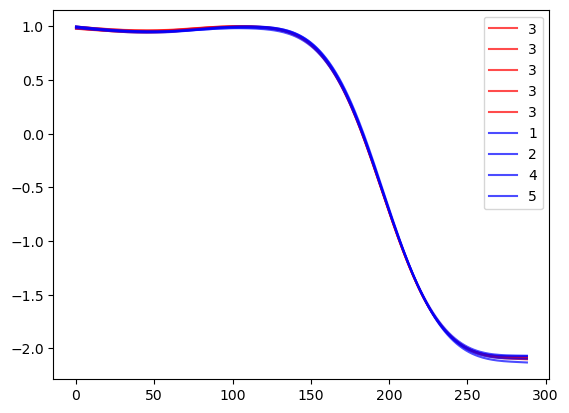

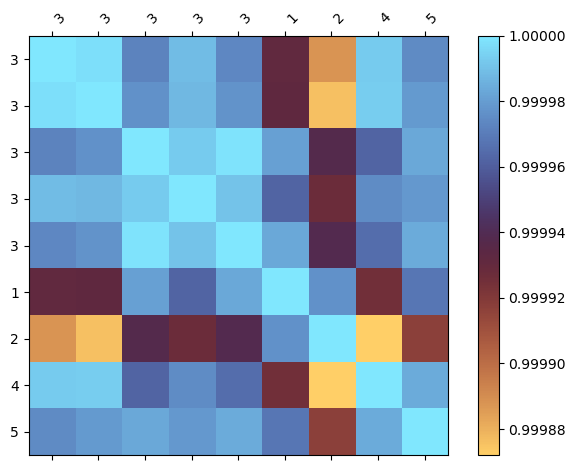

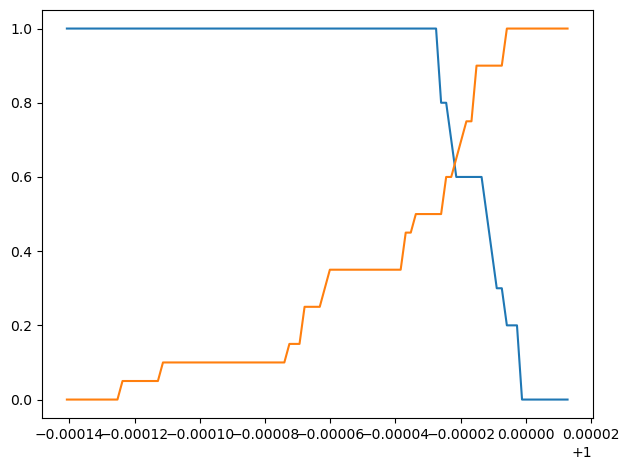

In [9]:
roi_map = {
    'tdp0604': (155, 445),
    'pi3hdx12211': (160, 450),
}
foo = list(roi_map.values())[0]
roi_n = foo[1] - foo[0]

def plot_covar(group_a, group_b, select_trace='open_fwd', select_channel='adc1', smooth=None, plot_cdf=False):
    group_a = sorted(group_a, key=lambda entry: entry['info']['serial'])
    group_b = sorted(group_b, key=lambda entry: entry['info']['serial'])
    all_traces = group_a + group_b
        
    d = np.zeros((len(all_traces), roi_n))
    labels = []
    for i, trace in enumerate(all_traces):
        trace_data = trace['data'][select_trace][select_channel]
        start, end = roi_map[trace['info']['chip']]
        trace_data = trace_data[start:end]

        if smooth is not None:
            t = np.linspace(0, 1, len(trace_data))
            spl = interpolate.make_smoothing_spline(t, trace_data, lam=smooth)
            trace_data = spl(t)
        
        d[i] = trace_data
        labels.append(str(trace['info']['serial']))
        
    
    # Normalize each curve such that its mean is at 0 and its min is at -1
    deltas = d[:,1:]
    deltas -= np.repeat(deltas.mean(axis=1)[:,np.newaxis], roi_n-1, axis=1)
    deltas /= np.repeat(deltas.max(axis=1)[:,np.newaxis], roi_n-1, axis=1)
    
    # Align all curves such that the trace starts where the trace crosses 0.5
    #roi_refined = round(np.mean(roi_n - 1 - np.argmax(deltas[:,::-1] > 0.5, axis=1))), roi_n
    #deltas = deltas[:,roi_refined[0]:roi_refined[1]]
    
    corr = np.corrcoef(deltas)
    
    fig, ax = plt.subplots()
    for i, (x, lab) in enumerate(zip(deltas, labels)):
        ax.plot(x, label=lab, color=('red' if i<len(group_a) else 'blue'), alpha=0.7)
    ax.legend()
    
    within_class = corr[:4, :4][np.triu_indices(4)]
    cross_class = corr[4:, :4].flatten()
    
    cdf = lambda x, mu, sigma: 1/2 * (1 + math.erf((x - mu) / (sigma * math.sqrt(2))))
    threshold = (np.mean(within_class) + np.mean(cross_class)) / 2
    print(f'Baseline threshold set at {threshold:.6f}')
    
    for name, data in [('Within', within_class), ('Cross', cross_class)]:
        print(f'{name} class: {np.mean(data):.3g}±{np.std(data):.3g} max: {np.max(data):.3g}')
    print(f'Baseline false negative probability: {cdf(threshold, np.mean(within_class), np.std(within_class)):.12f}')
    print(f'Baseline false positive probability: {1 - cdf(threshold, np.mean(cross_class), np.std(cross_class)):.12f}')
    
    #corr -= np.min(corr)
    #corr /= np.max(corr)
    
    #for i in range(len(corr[0])):
    #    corr[i, i] = math.nan
    
    fig, ax = plt.subplots()
    cax = ax.matshow(corr, interpolation='nearest', cmap='managua')
    fig.colorbar(cax)
    ax.set_xticks(list(range(len(labels))))
    ax.set_xticklabels(labels, rotation=45, ha='left')
    ax.set_yticks(list(range(len(labels))))
    ax.set_yticklabels(labels)
    fig.tight_layout()

    if plot_cdf:
        fig, ax = plt.subplots()
        all_classes = [0] * len(group_a) + [1] * len(group_b)
        min_corr = corr.min()
        max_corr = corr.max()
        d_corr = max_corr - min_corr
        x = np.linspace(min_corr - 0.1*d_corr, max_corr + 0.1 * d_corr, 100)

        correct_in_group = lambda thr: np.mean(corr[np.triu_indices(len(group_a), 1)] >= thr)
        correct_out_group = lambda thr: np.mean(corr[:len(group_a), len(group_a):] < thr)

        ax.plot(x, [correct_in_group(val) for val in x])
        ax.plot(x, [correct_out_group(val) for val in x])
        fig.tight_layout()
    #fig.savefig('../paper/manip_pearson_corr.pdf')

#group_a = [val for key, values in data.items() for val in values if val['info']['chip'] == 'pi3hdx12211' and key == 'M-SP-PITCH-V2-0001-0.4'][-5:]
#group_b = list({key: val for key, values in data.items() for val in values if val['info']['chip'] == 'pi3hdx12211' and re.match(r'M-SP-PITCH-V2-000[23456]-0\.4', key)}.values())

#group_a = [val for key, values in data.items() for val in values if val['info']['chip'] == 'tdp0604' and key == 'M-SP-PITCH-V2-0001-0.4'][-5:]
#group_b = list({key: val for key, values in data.items() for val in values if val['info']['chip'] == 'tdp0604' and re.match(r'M-SP-PITCH-V2-000[23456]-0\.4', key)}.values())
#plot_covar(group_a, group_b, select_trace='open_fwd', select_channel='adc1', smooth=None)

group_a = [val for key, values in data.items() for val in values if val['info']['chip'] == 'pi3hdx12211' and key == 'M-SP-PITCH-V2-0003-0.4'][-5:]
group_b = list({key: val for key, values in data.items() for val in values if val['info']['chip'] == 'pi3hdx12211' and re.match(r'M-SP-PITCH-V2-000[1245]-0\.4', key)}.values())
plot_covar(group_a, group_b, select_trace='open_fwd', smooth=1e-2, plot_cdf=True)

Baseline threshold set at 0.961379
Within class: 0.979±0.00182 min: 0.975 max: 0.983
Cross class: 0.944±0.00617 min: 0.934 max: 0.96
Baseline false negative probability: 0.000000000000
Baseline false positive probability: 0.002633563073


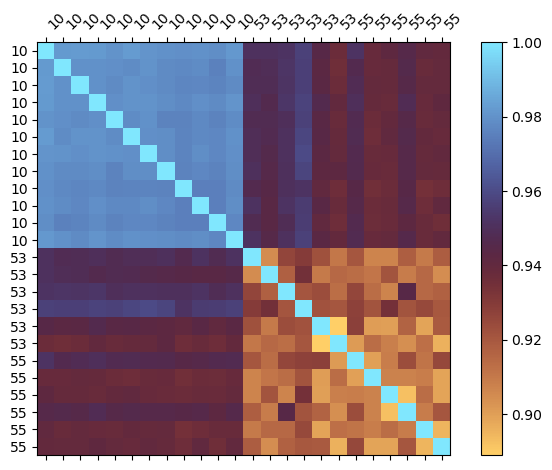

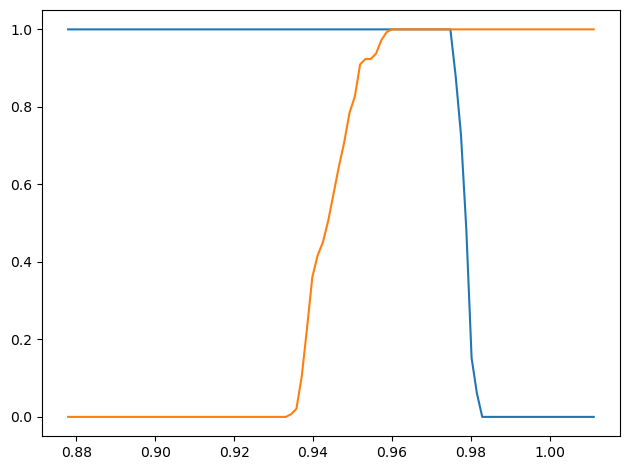

In [10]:
def plot_vector_covar(group_a, group_b, do_cal=False, vector_method='norm', distance_method='corr', smooth=None, plot_cdf=False):
    group_a = sorted(group_a, key=lambda entry: entry['info']['serial'])
    group_b = sorted(group_b, key=lambda entry: entry['info']['serial'])
    all_traces = group_a + group_b
        
    d = np.zeros((len(all_traces), 12, roi_n))
    labels = []
    for i, entry in enumerate(all_traces):
        start, end = roi_map[entry['info']['chip']]
        labels.append(entry['info']['serial'])
        for j, (term, direction, channel) in enumerate(itertools.product(['open', 'short', 'load'], ['fwd', 'flip'], ['adc1', 'adc2'])):
            trace_data = np.array(entry['data'][f'{term}_{direction}'][channel])
            if do_cal:
                trace_data -= np.array(entry['data']['cal'][channel])
                
            if smooth is not None:
                t = np.linspace(0, 1, len(trace_data))
                spl = interpolate.make_smoothing_spline(t, trace_data, lam=smooth)
                trace_data = spl(t)
            
            d[i, j] = trace_data[start:end]
    
    # Normalize each curve such that its mean is at 0 and its min is at -1
    deltas = d[:,:,1:]
    deltas -= np.repeat(deltas.mean(axis=2)[:,:,np.newaxis], roi_n-1, axis=2)
    deltas /= np.repeat(deltas.max(axis=2)[:,:,np.newaxis], roi_n-1, axis=2)
    
    # Align all curves such that the trace starts where the trace crosses 0.5
    #roi_refined = round(np.mean(roi_n - 1 - np.argmax(deltas[:,::-1] > 0.5, axis=1))), roi_n
    #deltas = deltas[:,roi_refined[0]:roi_refined[1]]

    corr = np.zeros((12, len(all_traces), len(all_traces)))
    for i in range(12):
        if distance_method == 'corr':
            corr[i] = np.corrcoef(deltas[:,i,:])
        elif distance_method == 'max':
            for k, l in itertools.product(range(len(all_traces)), repeat=2):
                corr[i, k, l] = 1 - np.abs(deltas[k,i,:] - deltas[l,i,:]).max()
        else:
            raise ValueError(f'invalid distance_method {distance_method!r}')

    if vector_method == 'norm':
        corr = np.sqrt(np.mean(np.square(corr), axis=0))
    elif vector_method == 'min':
        corr = np.min(corr, axis=0)
    else:
        raise ValueError(f'invalid vector_method {vector_method!r}')
    
    within_class = corr[:len(group_a), :len(group_a)][np.triu_indices(len(group_a), 1)]
    cross_class = corr[len(group_a):, :len(group_a)].flatten()
    
    cdf = lambda x, mu, sigma: 1/2 * (1 + math.erf((x - mu) / (sigma * math.sqrt(2))))
    threshold = (np.mean(within_class) + np.mean(cross_class)) / 2
    #threshold = np.mean(within_class) -2*np.std(within_class)
    #threshold = (np.min(within_class) + np.max(cross_class)) / 2
    print(f'Baseline threshold set at {threshold:.6f}')
    
    for name, data in [('Within', within_class), ('Cross', cross_class)]:
        print(f'{name} class: {np.mean(data):.3g}±{np.std(data):.3g} min: {np.min(data):.3g} max: {np.max(data):.3g}')
    print(f'Baseline false negative probability: {cdf(threshold, np.mean(within_class), np.std(within_class)):.12f}')
    print(f'Baseline false positive probability: {1 - cdf(threshold, np.mean(cross_class), np.std(cross_class)):.12f}')
    
    #corr -= np.min(corr)
    #corr /= np.max(corr)
    
    #for i in range(len(corr[0])):
    #    corr[i, i] = math.nan
    
    fig, ax = plt.subplots()
    cax = ax.matshow(corr, interpolation='nearest', cmap='managua')
    fig.colorbar(cax)
    ax.set_xticks(list(range(len(labels))))
    ax.set_xticklabels(labels, rotation=45, ha='left')
    ax.set_yticks(list(range(len(labels))))
    ax.set_yticklabels(labels)
    fig.tight_layout()

    if plot_cdf:
        fig, ax = plt.subplots()
        all_classes = [0] * len(group_a) + [1] * len(group_b)
        min_corr = corr.min()
        max_corr = corr.max()
        d_corr = max_corr - min_corr
        x = np.linspace(min_corr - 0.1*d_corr, max_corr + 0.1 * d_corr, 100)

        correct_in_group = lambda thr: np.mean(corr[np.triu_indices(len(group_a), 1)] >= thr)
        correct_out_group = lambda thr: np.mean(corr[:len(group_a), len(group_a):] < thr)

        ax.plot(x, [correct_in_group(val) for val in x])
        ax.plot(x, [correct_out_group(val) for val in x])
        fig.tight_layout()
    #fig.savefig('../paper/manip_pearson_corr.pdf')

#group_a = [val for key, values in data.items() for val in values if val['info']['chip'] == 'pi3hdx12211' and key == 'M-SP-PITCH-V2-0003-0.4'][-5:]
#group_b = list({key: val for key, values in data.items() for val in values if val['info']['chip'] == 'pi3hdx12211' and re.match(r'M-SP-PITCH-V2-000[1245]-0\.4', key)}.values())
#plot_vector_covar(group_a, group_b, distance_method='corr', smooth=None)

group_baseline = [value for value in data['M-SP-PITCH-V2-0010-0.3'] if value['info']['meta'] == 'probe-interleave-25-07-02-01-p0.3'][:12]
group_probed = [value for entries in data.values() for value in entries if value['info']['meta'] == 'probe-interleave-25-07-02-01-p0.3' and 'probe_points' in value['info']['mods']]
plot_vector_covar(group_baseline, group_probed, vector_method='norm', distance_method='corr', plot_cdf=True)

## Can we distinguish one specimen from other specimens with the same layout?

Baseline threshold set at 0.969298
Within class: 0.97±0.00132 min: 0.968 max: 0.972
Cross class: 0.969±0.00174 min: 0.966 max: 0.973
Baseline false negative probability: 0.368654596913
Baseline false positive probability: 0.399591556060


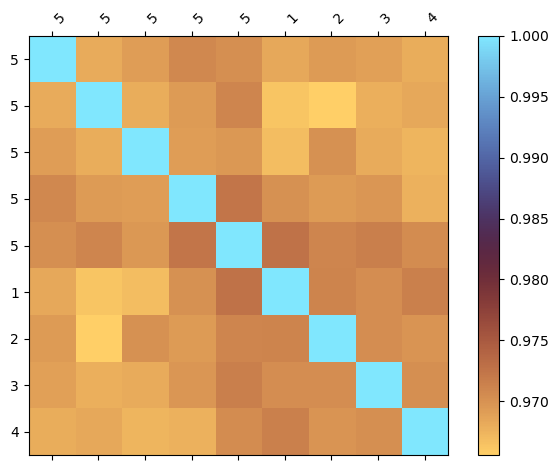

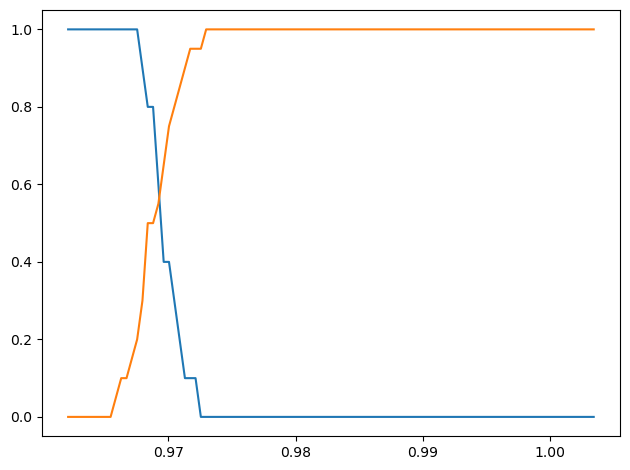

In [11]:
group_a = [val for key, values in data.items() for val in values if val['info']['chip'] == 'pi3hdx12211' and key == 'M-SP-PITCH-V2-0005-0.4'][-5:]
group_b = list({key: val for key, values in data.items() for val in values if val['info']['chip'] == 'pi3hdx12211' and re.match(r'M-SP-PITCH-V2-000[1234]-0\.4', key)}.values())
plot_vector_covar(group_a, group_b, plot_cdf=True)

## Can we distinguish mesh layout variants?

Compare measurements of five specimens of the base layout against measurements of each of the four alternate layouts.

Baseline threshold set at 0.944277
Within class: 0.971±0.000794 min: 0.97 max: 0.973
Cross class: 0.918±0.0392 min: 0.85 max: 0.949
Baseline false negative probability: 0.000000000000
Baseline false positive probability: 0.248930955478


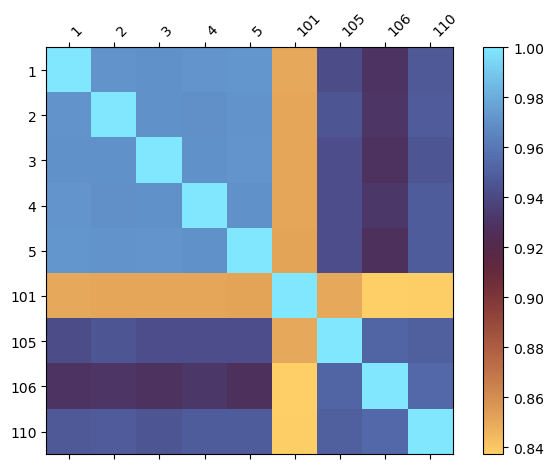

In [12]:
group_a = list({key: val for key, values in data.items() for val in values if val['info']['chip'] == 'pi3hdx12211' and re.match(r'M-SP-PITCH-V2-000[12345]-0\.4', key)}.values())
group_b = list({val['info']['mesh_layout']: val for key, values in data.items() for val in values if val['info']['chip'] == 'pi3hdx12211' and 'ALT' in val['info']['mesh_layout']}.values())
plot_vector_covar(group_a, group_b)

#### Same measurement, but show TPD0604 data 

Baseline threshold set at 0.988280
Within class: 0.997±0.00035 min: 0.996 max: 0.997
Cross class: 0.98±0.0243 min: 0.935 max: 0.995
Baseline false negative probability: 0.000000000000
Baseline false positive probability: 0.361190446191


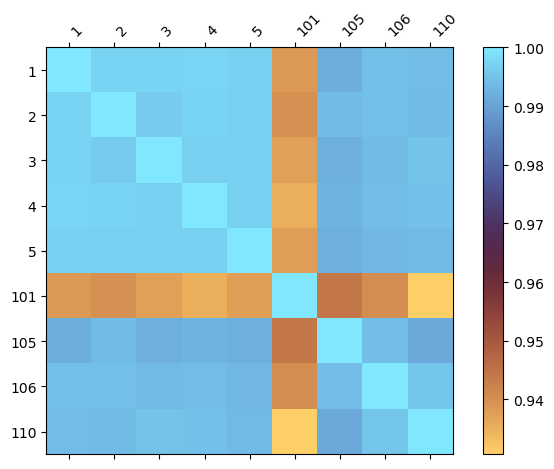

In [13]:
group_a = list({key: val for key, values in data.items() for val in values if val['info']['chip'] == 'tdp0604' and re.match(r'M-SP-PITCH-V2-000[12345]-0\.4', key)}.values())
group_b = list({val['info']['mesh_layout']: val for key, values in data.items() for val in values if val['info']['chip'] == 'tdp0604' and 'ALT' in val['info']['mesh_layout']}.values())
plot_vector_covar(group_a, group_b, do_cal=False)

Baseline threshold set at 0.872258
Within class: 0.975±0.00591 min: 0.966 max: 0.981
Cross class: 0.769±0.211 min: 0.488 max: 0.983
Baseline false negative probability: 0.000000000000
Baseline false positive probability: 0.313260823987


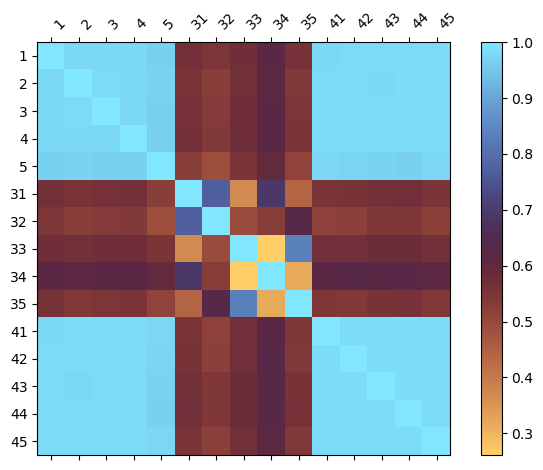

In [14]:
plot_vector_covar(mod_baseline[0.3], mod_modified['short_across_traces', 0.3])

Baseline threshold set at 0.701013
Within class: 0.975±0.00591 min: 0.966 max: 0.981
Cross class: 0.427±0.0442 min: 0.334 max: 0.489
Baseline false negative probability: 0.000000000000
Baseline false positive probability: 0.000000000271


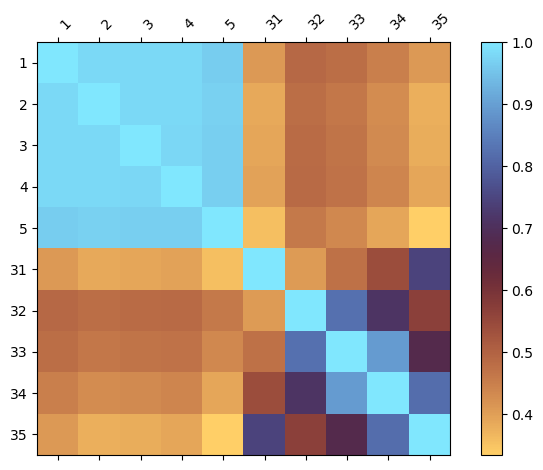

In [15]:
plot_vector_covar(mod_baseline[0.3], mod_modified['short_across_traces', 0.4])

Baseline threshold set at 0.648934
Within class: 0.975±0.00591 min: 0.966 max: 0.981
Cross class: 0.323±0.0409 min: 0.24 max: 0.374
Baseline false negative probability: 0.000000000000
Baseline false positive probability: 0.000000000000


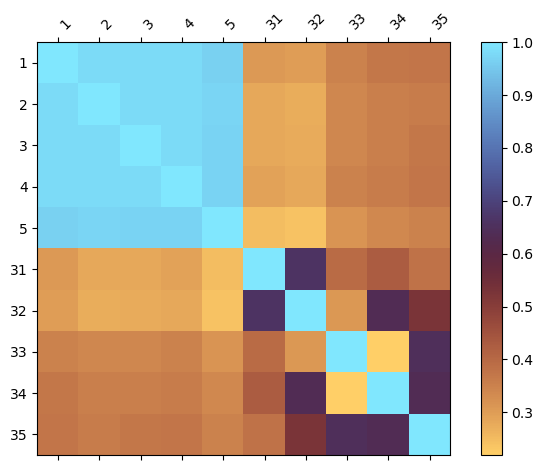

In [16]:
plot_vector_covar(mod_baseline[0.3], mod_modified['short_across_traces', 0.6])

Baseline threshold set at 0.584805
Within class: 0.975±0.00591 min: 0.966 max: 0.981
Cross class: 0.195±0.0352 min: 0.148 max: 0.265
Baseline false negative probability: 0.000000000000
Baseline false positive probability: 0.000000000000


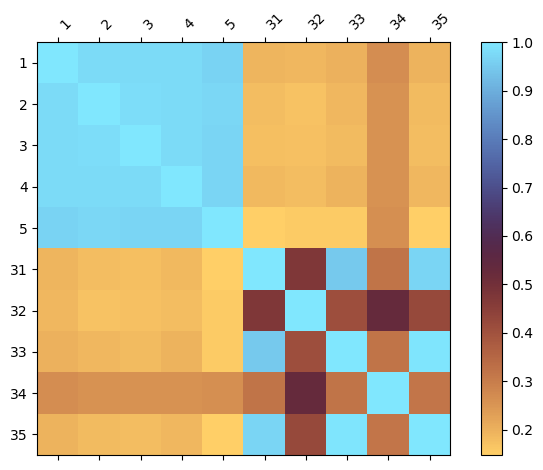

In [17]:
plot_vector_covar(mod_baseline[0.3], mod_modified['short_across_traces', 1.0])

Baseline threshold set at 0.912746
Within class: 0.975±0.00591 min: 0.966 max: 0.981
Cross class: 0.85±0.13 min: 0.663 max: 0.983
Baseline false negative probability: 0.000000000000
Baseline false positive probability: 0.316362110922


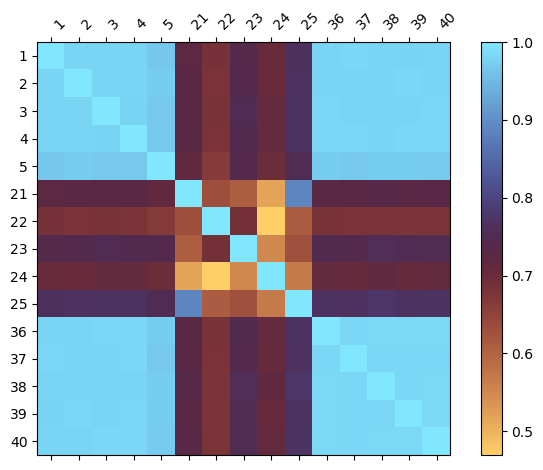

In [18]:
plot_vector_covar(mod_baseline[0.3], mod_modified['open', 0.3])

Baseline threshold set at 0.760797
Within class: 0.975±0.00591 min: 0.966 max: 0.981
Cross class: 0.547±0.0224 min: 0.494 max: 0.573
Baseline false negative probability: 0.000000000000
Baseline false positive probability: 0.000000000000


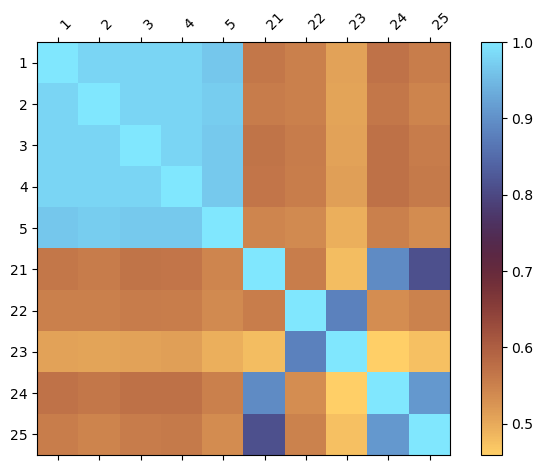

In [19]:
plot_vector_covar(mod_baseline[0.3], mod_modified['open', 0.4])

Baseline threshold set at 0.677484
Within class: 0.975±0.00591 min: 0.966 max: 0.981
Cross class: 0.38±0.0891 min: 0.276 max: 0.548
Baseline false negative probability: 0.000000000000
Baseline false positive probability: 0.000422552353


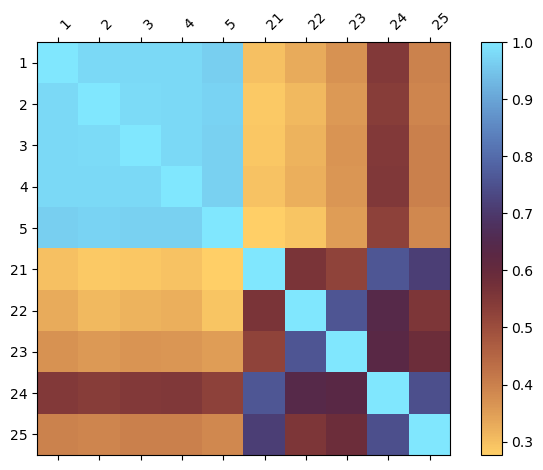

In [20]:
plot_vector_covar(mod_baseline[0.3], mod_modified['open', 0.6])

Baseline threshold set at 0.625650
Within class: 0.975±0.00591 min: 0.966 max: 0.981
Cross class: 0.276±0.0863 min: 0.192 max: 0.467
Baseline false negative probability: 0.000000000000
Baseline false positive probability: 0.000025844305


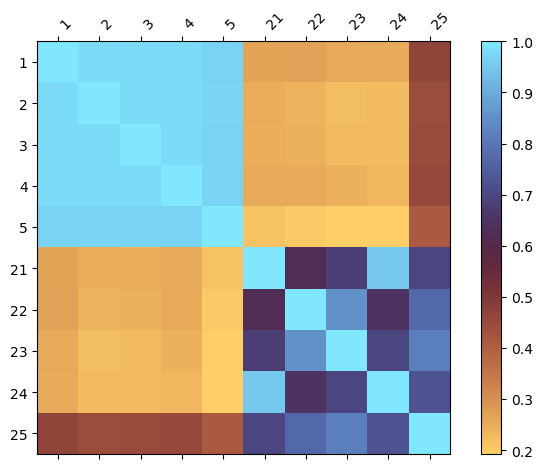

In [21]:
plot_vector_covar(mod_baseline[0.3], mod_modified['open', 1.0])

Baseline threshold set at 0.966650
Within class: 0.998±0.00182 min: 0.994 max: 0.999
Cross class: 0.936±0.0925 min: 0.73 max: 0.999
Baseline false negative probability: 0.000000000000
Baseline false positive probability: 0.369113737192


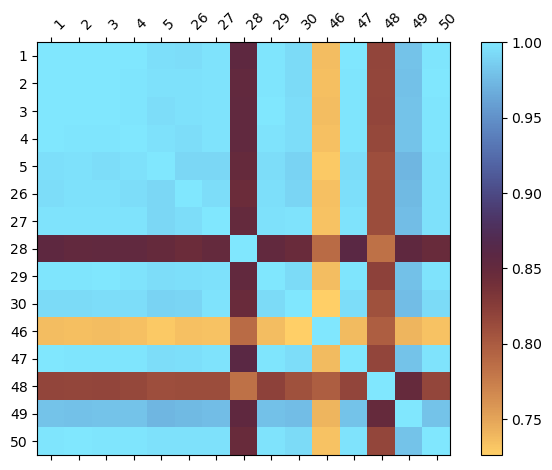

In [22]:
plot_vector_covar(mod_baseline[0.3], mod_modified['short_within_trace', 0.3], distance_method='corr', vector_method='norm', smooth=1e-5)

Baseline threshold set at 0.929626
Within class: 0.999±0.000803 max: 1
Cross class: 0.86±0.219 max: 1
Baseline false negative probability: 0.000000000000
Baseline false positive probability: 0.375276121399


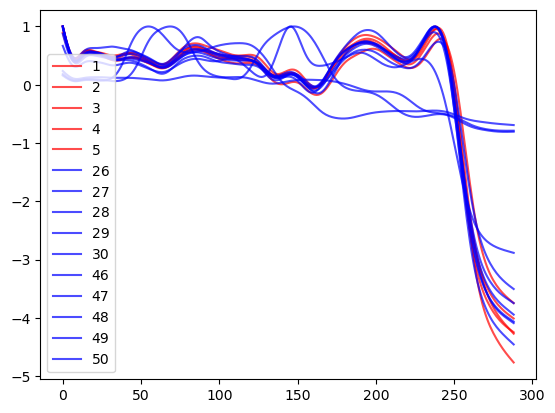

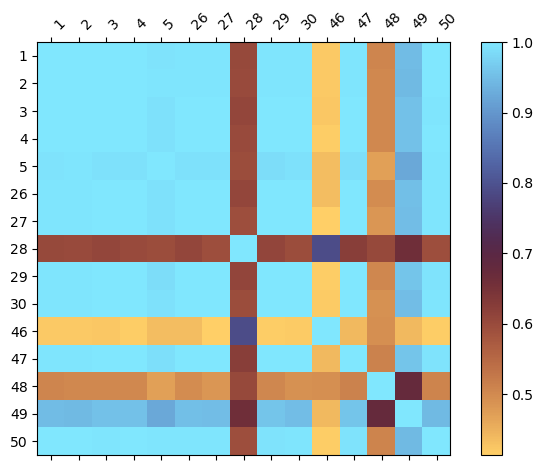

In [23]:
plot_covar(mod_baseline[0.3], mod_modified['short_within_trace', 0.3], select_trace='open_fwd', select_channel='adc1', smooth=1e-5)

Baseline threshold set at 0.802358
Within class: 0.975±0.00591 min: 0.966 max: 0.981
Cross class: 0.63±0.0632 min: 0.494 max: 0.704
Baseline false negative probability: 0.000000000000
Baseline false positive probability: 0.003157026813


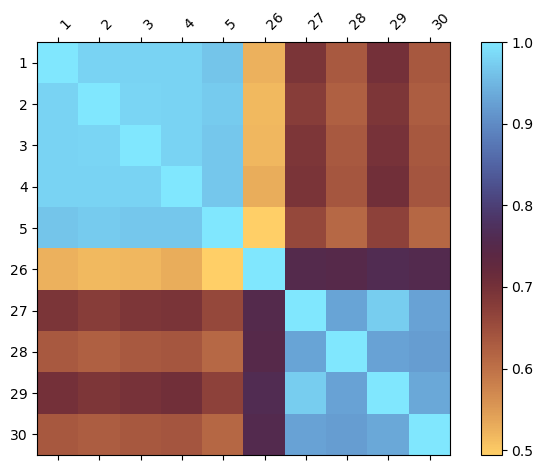

In [24]:
plot_vector_covar(mod_baseline[0.3], mod_modified['short_within_trace', 0.4])

Baseline threshold set at 0.658450
Within class: 0.975±0.00591 min: 0.966 max: 0.981
Cross class: 0.342±0.00931 min: 0.318 max: 0.353
Baseline false negative probability: 0.000000000000
Baseline false positive probability: 0.000000000000


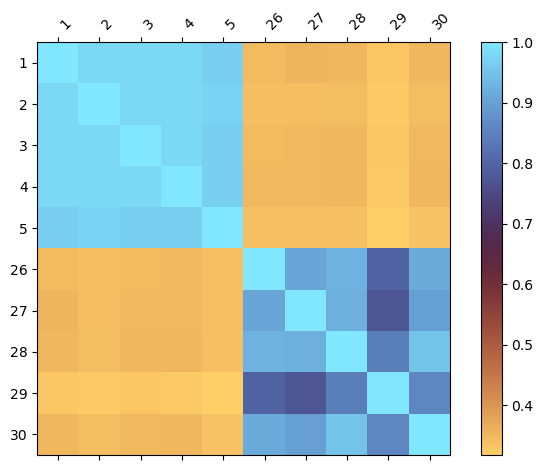

In [25]:
plot_vector_covar(mod_baseline[0.3], mod_modified['short_within_trace', 0.6])

Baseline threshold set at 0.621328
Within class: 0.975±0.00591 min: 0.966 max: 0.981
Cross class: 0.268±0.0242 min: 0.218 max: 0.313
Baseline false negative probability: 0.000000000000
Baseline false positive probability: 0.000000000000


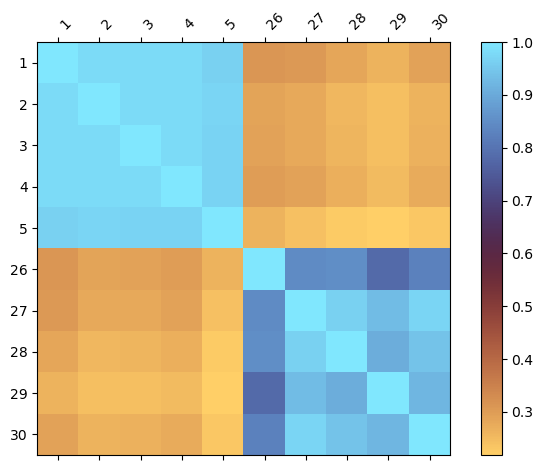

In [26]:
plot_vector_covar(mod_baseline[0.3], mod_modified['short_within_trace', 1.0])

Baseline threshold set at 0.956638
Within class: 0.998±0.000879 min: 0.996 max: 0.999
Cross class: 0.916±0.109 min: 0.703 max: 0.999
Baseline false negative probability: 0.000000000000
Baseline false positive probability: 0.352476829164
Baseline threshold set at 0.814067
Within class: 0.991±0.0031 min: 0.984 max: 0.996
Cross class: 0.637±0.421 min: -0.132 max: 0.993
Baseline false negative probability: 0.000000000000
Baseline false positive probability: 0.337040576195
Baseline threshold set at 0.897095
Within class: 0.891±0.0293 min: 0.828 max: 0.945
Cross class: 0.904±0.109 min: 0.739 max: 1.13
Baseline false negative probability: 0.586668632687
Baseline false positive probability: 0.523407808138
Baseline threshold set at -0.141600
Within class: 0.599±0.13 min: 0.252 max: 0.845
Cross class: -0.882±1.38 min: -3.02 max: 0.716
Baseline false negative probability: 0.000000006096
Baseline false positive probability: 0.295206150680


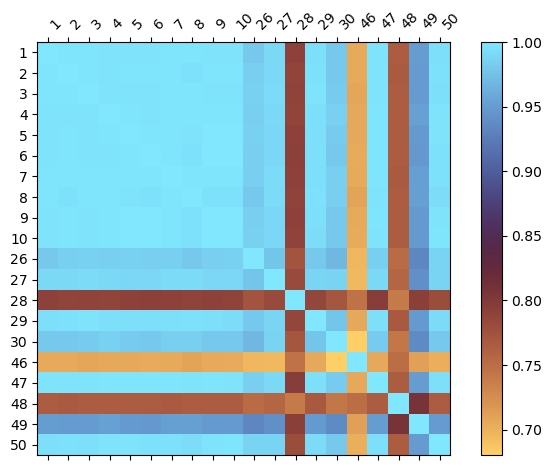

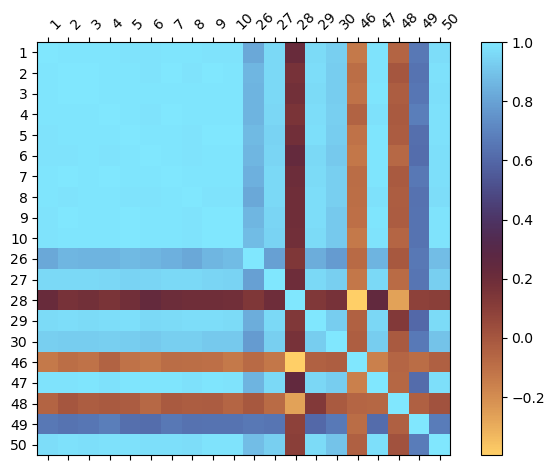

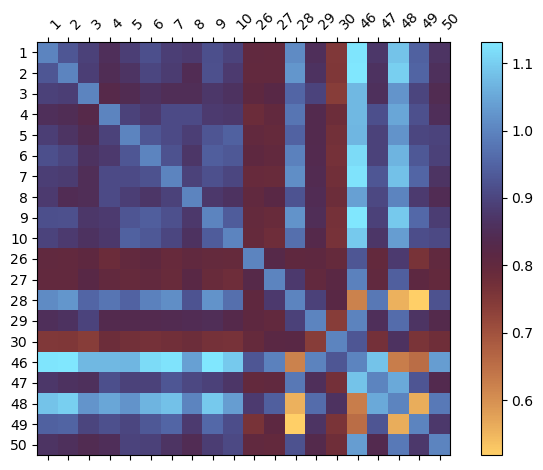

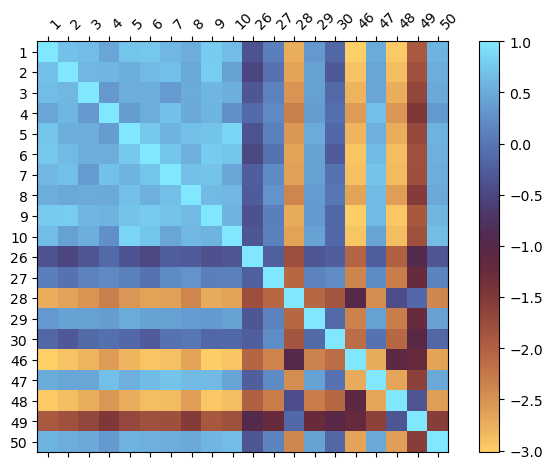

In [27]:
entries = [value for entry in data.values() for value in entry if value['info']['meta'] == 'interleaved-25-07-02-01-p0.3']
group_baseline = [value for value in entries if not value['info']['mods']]
group_modified = [value for value in entries if value['info']['mods']]

smooth = 1e-6
plot_vector_covar(group_baseline, group_modified, vector_method='norm', distance_method='corr', smooth=smooth)
plot_vector_covar(group_baseline, group_modified, vector_method='min', distance_method='corr', smooth=smooth)
plot_vector_covar(group_baseline, group_modified, vector_method='norm', distance_method='max', smooth=smooth)
plot_vector_covar(group_baseline, group_modified, vector_method='min', distance_method='max', smooth=smooth)

Baseline threshold set at 0.933157
Within class: 0.98±0.00188 min: 0.975 max: 0.983
Cross class: 0.886±0.106 min: 0.699 max: 0.982
Baseline false negative probability: 0.000000000000
Baseline false positive probability: 0.328457736961


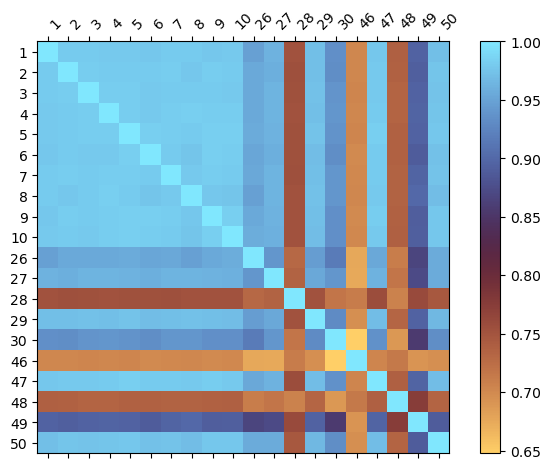

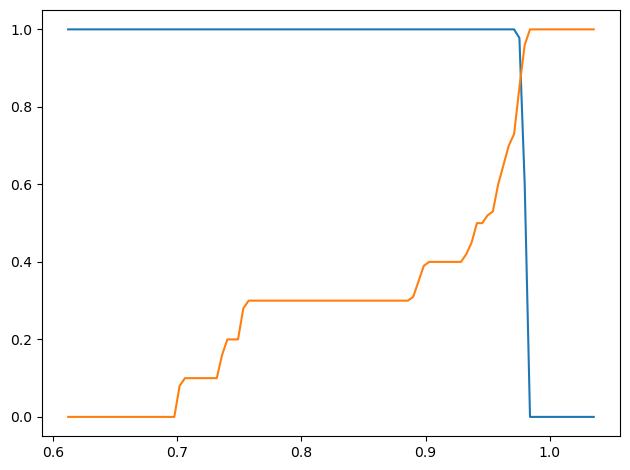

In [28]:
entries = [value for entry in data.values() for value in entry if value['info']['meta'] == 'interleaved-25-07-02-01-p0.3']
group_baseline = [value for value in entries if not value['info']['mods']]
group_modified = [value for value in entries if value['info']['mods']]

smooth = None
plot_vector_covar(group_baseline, group_modified, vector_method='norm', distance_method='corr', smooth=smooth, plot_cdf=True)

Baseline threshold set at 0.960699
Within class: 0.995±0.00115 min: 0.991 max: 0.997
Cross class: 0.926±0.0893 min: 0.783 max: 0.996
Baseline false negative probability: 0.000000000000
Baseline false positive probability: 0.349249068037
Baseline threshold set at 0.857937
Within class: 0.988±0.00299 min: 0.98 max: 0.993
Cross class: 0.728±0.353 min: -0.0684 max: 0.991
Baseline false negative probability: 0.000000000000
Baseline false positive probability: 0.356244523468
Baseline threshold set at 0.768749
Within class: 0.86±0.0223 min: 0.793 max: 0.893
Cross class: 0.677±0.135 min: 0.397 max: 0.863
Baseline false negative probability: 0.000020032212
Baseline false positive probability: 0.248659653963
Baseline threshold set at 0.355298
Within class: 0.734±0.0925 min: 0.486 max: 0.847
Cross class: -0.0231±0.645 min: -1.28 max: 0.785
Baseline false negative probability: 0.000021403026
Baseline false positive probability: 0.278601943741


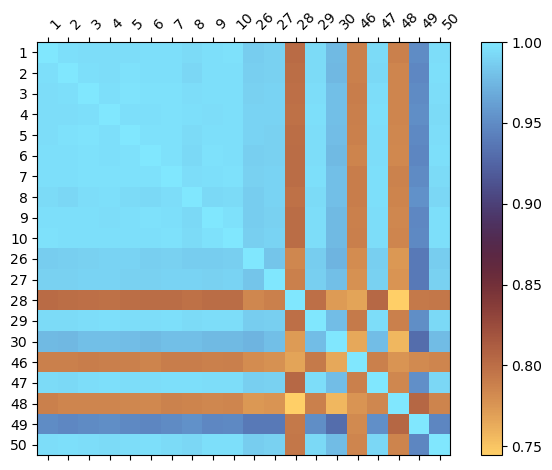

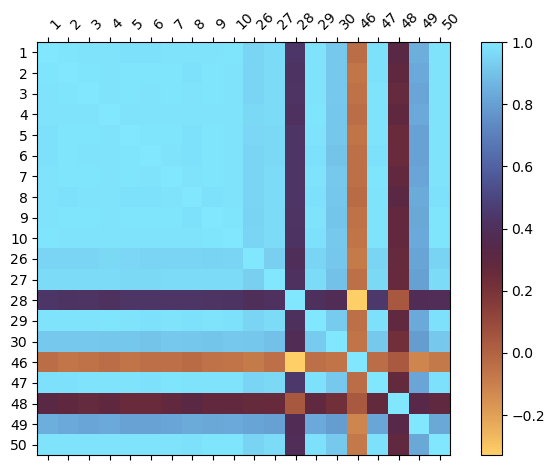

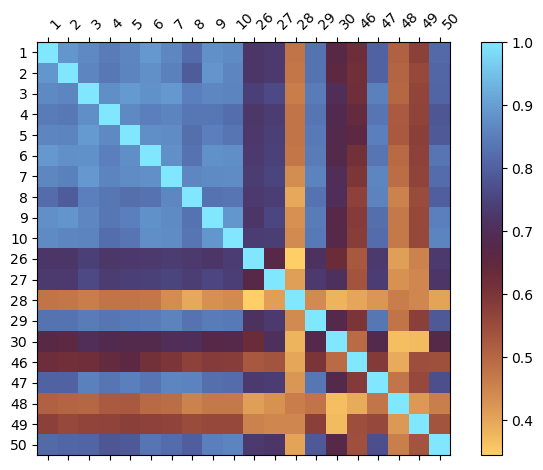

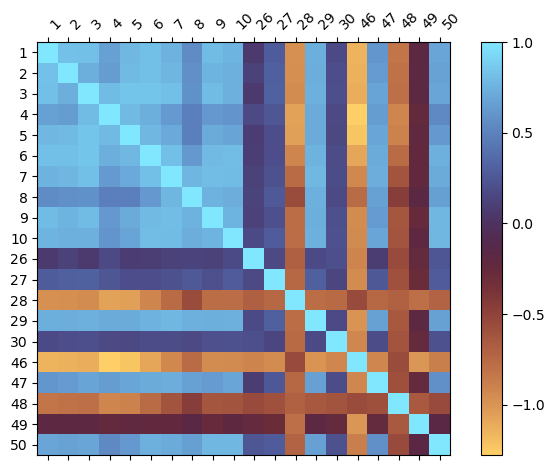

In [29]:
entries = [value for entry in data.values() for value in entry if value['info']['meta'] == 'interleaved-25-07-02-02-p0.3']
group_baseline = [value for value in entries if not value['info']['mods']]
group_modified = [value for value in entries if value['info']['mods']]

smooth = None
plot_vector_covar(group_baseline, group_modified, vector_method='norm', distance_method='corr', smooth=smooth)
plot_vector_covar(group_baseline, group_modified, vector_method='min', distance_method='corr', smooth=smooth)
plot_vector_covar(group_baseline, group_modified, vector_method='norm', distance_method='max', smooth=smooth)
plot_vector_covar(group_baseline, group_modified, vector_method='min', distance_method='max', smooth=smooth)

tdp0604 tdp0604
[['short_within_trace'], ['short_within_trace'], ['short_within_trace'], ['short_within_trace'], ['short_within_trace'], ['short_within_trace'], ['short_within_trace'], ['short_within_trace'], ['short_within_trace'], ['short_within_trace']]
Baseline threshold set at 0.960838
Within class: 0.996±0.000496 min: 0.995 max: 0.998
Cross class: 0.925±0.0896 min: 0.783 max: 0.996
Baseline false negative probability: 0.000000000000
Baseline false positive probability: 0.345801726082
Baseline threshold set at 0.857032
Within class: 0.989±0.00226 min: 0.985 max: 0.994
Cross class: 0.725±0.358 min: -0.0808 max: 0.991
Baseline false negative probability: 0.000000000000
Baseline false positive probability: 0.355768389397
Baseline threshold set at 0.773742
Within class: 0.903±0.00772 min: 0.879 max: 0.921
Cross class: 0.644±0.151 min: 0.373 max: 0.87
Baseline false negative probability: 0.000000000000
Baseline false positive probability: 0.196044559641
Baseline threshold set at 0.4587

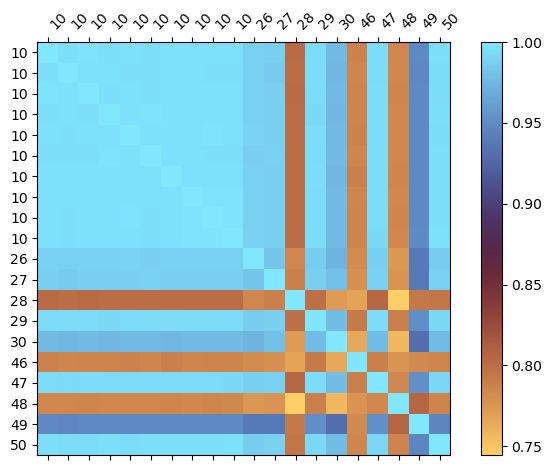

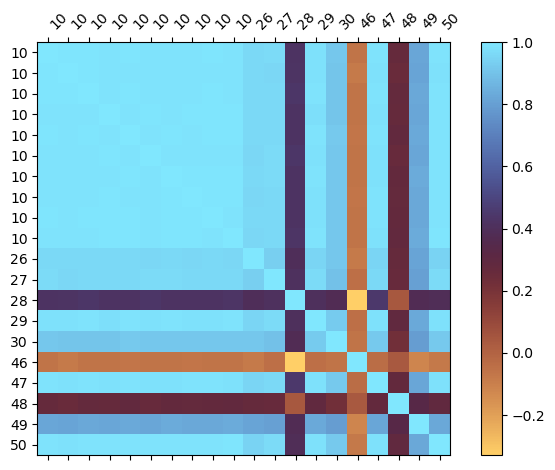

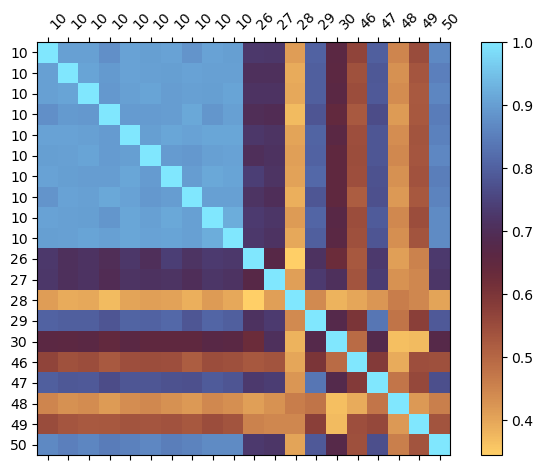

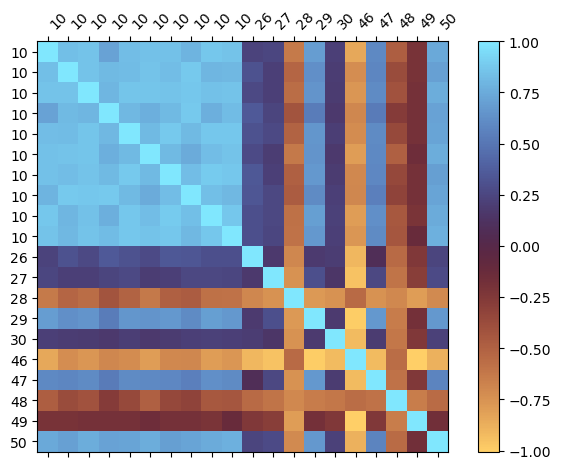

In [30]:
entries = [value for entry in data.values() for value in entry if value['info']['meta'] == 'interleaved-25-07-02-02-p0.3']
entries_repeat = [value for entry in data.values() for value in entry if value['info']['meta'] == 'baseline-repeat-25-07-02-01-p0.3']
print(entries[0]['info']['chip'], entries_repeat[0]['info']['chip'])
group_baseline = [value for value in entries_repeat if not value['info']['mods']][:10]
group_modified = [value for value in entries if value['info']['mods']]
print([value['info']['mods'] for value in group_modified])

smooth = None
plot_vector_covar(group_baseline, group_modified, vector_method='norm', distance_method='corr', smooth=smooth)
plot_vector_covar(group_baseline, group_modified, vector_method='min', distance_method='corr', smooth=smooth)
plot_vector_covar(group_baseline, group_modified, vector_method='norm', distance_method='max', smooth=smooth) 
plot_vector_covar(group_baseline, group_modified, vector_method='min', distance_method='max', smooth=smooth)

tdp0604 tdp0604
Baseline threshold set at 0.960838
Within class: 0.996±0.000496 min: 0.995 max: 0.998
Cross class: 0.925±0.0896 min: 0.783 max: 0.996
Baseline false negative probability: 0.000000000000
Baseline false positive probability: 0.345801726082


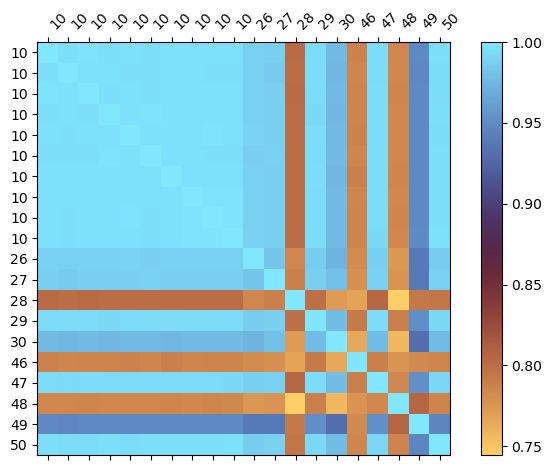

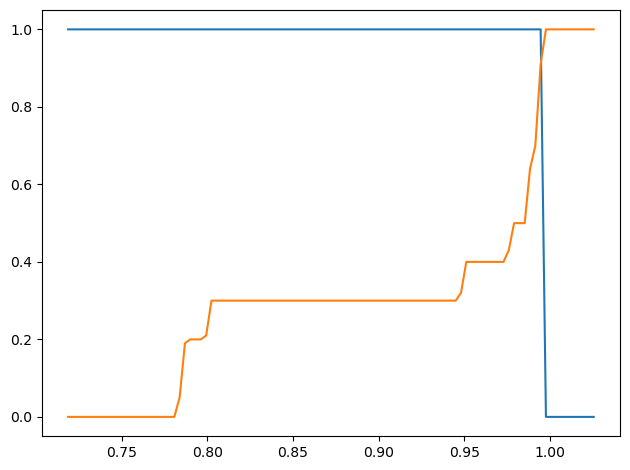

In [31]:
entries = [value for entry in data.values() for value in entry if value['info']['meta'] == 'interleaved-25-07-02-02-p0.3']
entries_repeat = [value for entry in data.values() for value in entry if value['info']['meta'] == 'baseline-repeat-25-07-02-01-p0.3']
print(entries[0]['info']['chip'], entries_repeat[0]['info']['chip'])
group_baseline = [value for value in entries_repeat if not value['info']['mods']][:10]
group_modified = [value for value in entries if value['info']['mods']]

smooth = None
plot_vector_covar(group_baseline, group_modified, vector_method='norm', distance_method='corr', smooth=smooth, plot_cdf=True)

pi3hdx12211
Baseline threshold set at 0.961379
Within class: 0.979±0.00182 min: 0.975 max: 0.983
Cross class: 0.944±0.00617 min: 0.934 max: 0.96
Baseline false negative probability: 0.000000000000
Baseline false positive probability: 0.002633563073


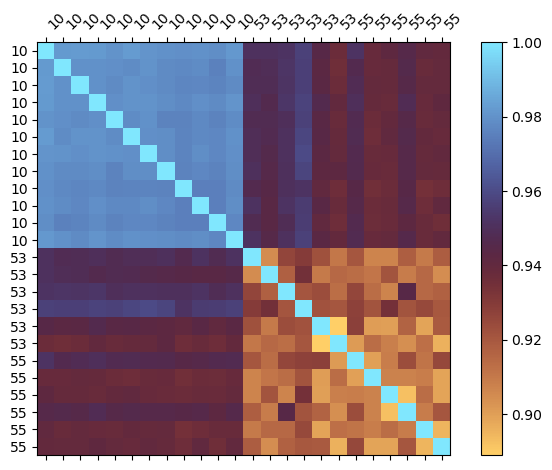

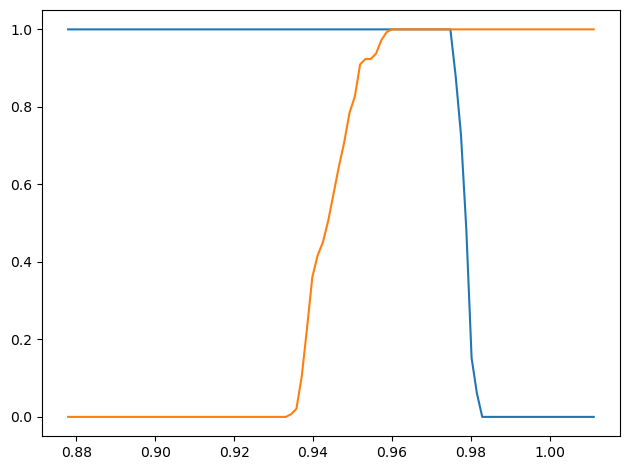

In [32]:
# probed with rigol PVP3150 probe, connected to running Rigol DS1054Z scope. probe grounded using ground clip to mesh specimen board ground area
# baseline also measured with ground clip connected to exclude grounding as the measured effect
group_baseline = [value for value in data['M-SP-PITCH-V2-0010-0.3'] if value['info']['meta'] == 'probe-interleave-25-07-02-01-p0.3'][:12]
group_probed = [value for entries in data.values() for value in entries if value['info']['meta'] == 'probe-interleave-25-07-02-01-p0.3' and 'probe_points' in value['info']['mods']]
print(group_baseline[0]['info']['chip'])

smooth = None
plot_vector_covar(group_baseline, group_probed, vector_method='norm', distance_method='corr', smooth=smooth, plot_cdf=True)

Baseline threshold set at 0.951092
Within class: 0.972±0.00261 min: 0.965 max: 0.976
Cross class: 0.93±0.00368 min: 0.919 max: 0.937
Baseline false negative probability: 0.000000000000
Baseline false positive probability: 0.000000009101


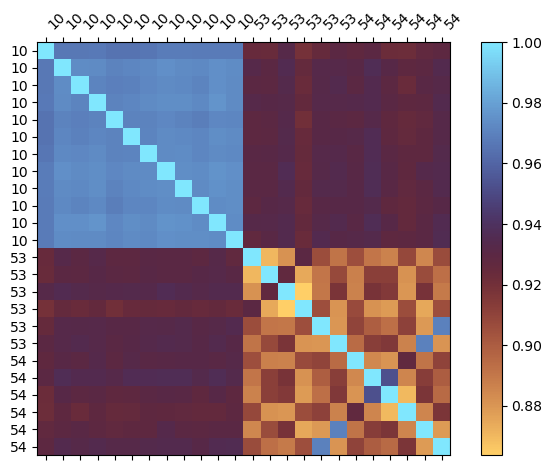

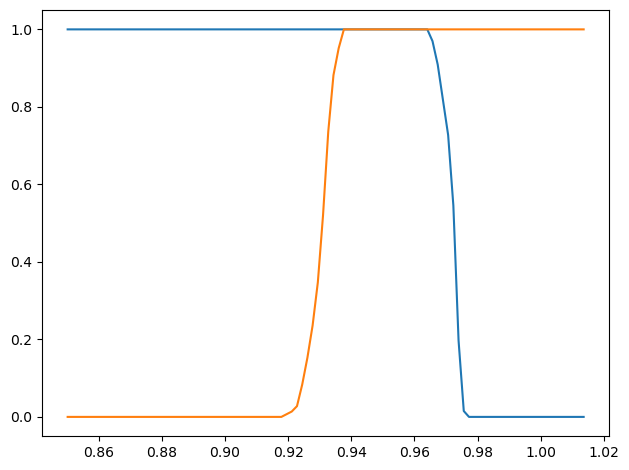

In [33]:
group_baseline = [value for value in data['M-SP-PITCH-V2-0010-0.4'] if value['info']['meta'] == 'probe-interleave-25-07-02-01-p0.4'][:12]
group_probed = [value for entries in data.values() for value in entries if value['info']['meta'] == 'probe-interleave-25-07-02-01-p0.4' and 'probe_points' in value['info']['mods']]

smooth = None
plot_vector_covar(group_baseline, group_probed, vector_method='norm', distance_method='corr', smooth=smooth, plot_cdf=True)

Baseline threshold set at 0.953939
Within class: 0.984±0.00094 min: 0.982 max: 0.986
Cross class: 0.924±0.0132 min: 0.89 max: 0.948
Baseline false negative probability: 0.000000000000
Baseline false positive probability: 0.011374090429


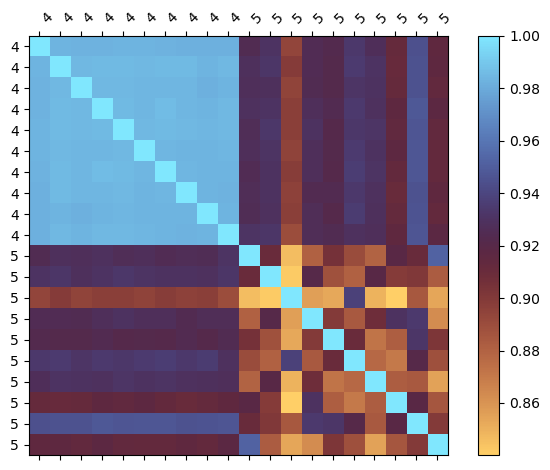

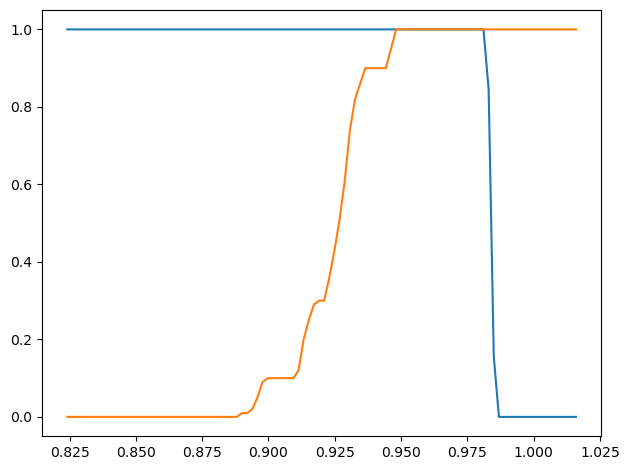

In [34]:
group_baseline = [value for value in data['M-SP-PITCH-V2-0004-0.3'] if value['info']['meta'] == 'touch-interleave-touch-serial-5-25-07-02-01-p0.3'][:10]
group_touch = [value for value in data['M-SP-PITCH-V2-0005-0.3'] if value['info']['meta'] == 'touch-interleave-touch-serial-5-25-07-02-01-p0.3'][:10]

smooth = None
plot_vector_covar(group_baseline, group_touch, vector_method='norm', distance_method='corr', smooth=smooth, plot_cdf=True)

Baseline threshold set at 0.983298
Within class: 0.984±0.000888 min: 0.982 max: 0.986
Cross class: 0.982±0.000887 min: 0.981 max: 0.985
Baseline false negative probability: 0.144158897703
Baseline false positive probability: 0.143935028357


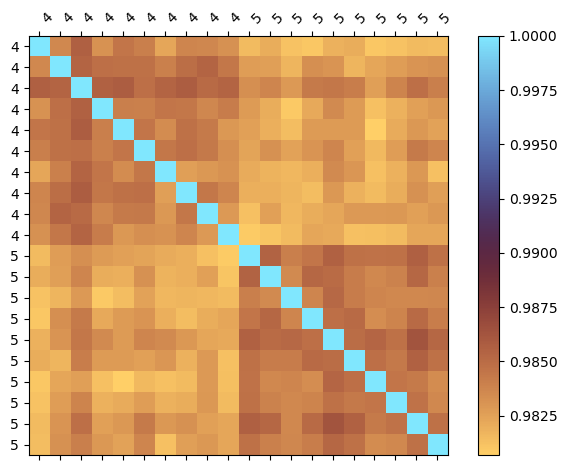

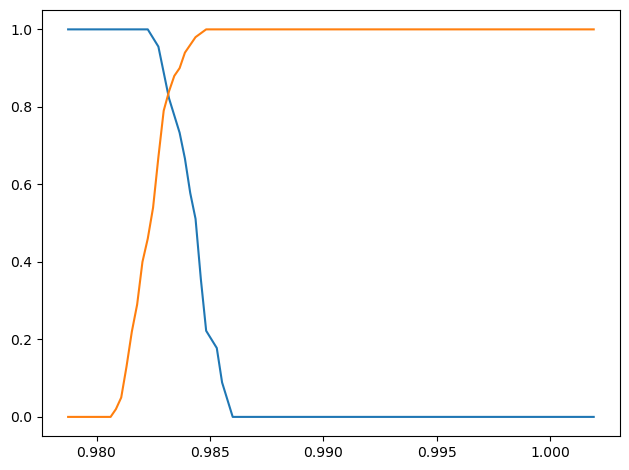

In [35]:
group_baseline = [value for value in data['M-SP-PITCH-V2-0004-0.3'] if value['info']['meta'] == 'touch-ground-interleave-touch-serial-5-25-07-02-01-p0.3'][:10]
group_touch = [value for value in data['M-SP-PITCH-V2-0005-0.3'] if value['info']['meta'] == 'touch-ground-interleave-touch-serial-5-25-07-02-01-p0.3'][:10]

smooth = None
plot_vector_covar(group_baseline, group_touch, vector_method='norm', distance_method='corr', smooth=smooth, plot_cdf=True)

Baseline threshold set at 0.968515
Within class: 0.984±0.00094 min: 0.982 max: 0.986
Cross class: 0.953±0.0306 min: 0.89 max: 0.985
Baseline false negative probability: 0.000000000000
Baseline false positive probability: 0.306841485128


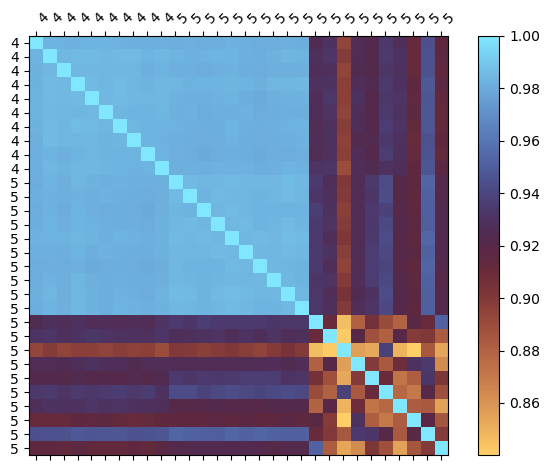

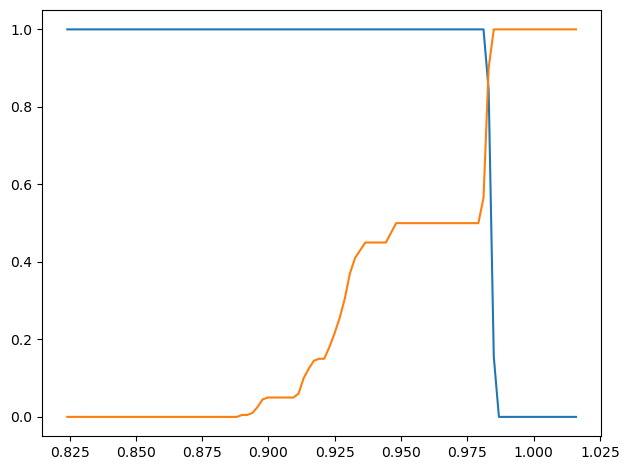

In [36]:
# touch group: touched with one or more fingers directly to the mesh surface
# ground group: ground plane of mesh specimen board firmly touched, but mesh not touched directly
group_baseline = [value for value in data['M-SP-PITCH-V2-0004-0.3'] if value['info']['meta'] == 'touch-interleave-touch-serial-5-25-07-02-01-p0.3'][:10]
group_touch_ground = [value for value in data['M-SP-PITCH-V2-0005-0.3'] if value['info']['meta'] == 'touch-ground-interleave-touch-serial-5-25-07-02-01-p0.3'][:10]
group_touch = [value for value in data['M-SP-PITCH-V2-0005-0.3'] if value['info']['meta'] == 'touch-interleave-touch-serial-5-25-07-02-01-p0.3'][:10]

smooth = None
plot_vector_covar(group_baseline, group_touch_ground + group_touch, vector_method='norm', distance_method='corr', smooth=smooth, plot_cdf=True)

Baseline threshold set at 0.973977
Within class: 0.983±0.000806 min: 0.981 max: 0.984
Cross class: 0.965±0.0058 min: 0.946 max: 0.972
Baseline false negative probability: 0.000000000000
Baseline false positive probability: 0.069349012210


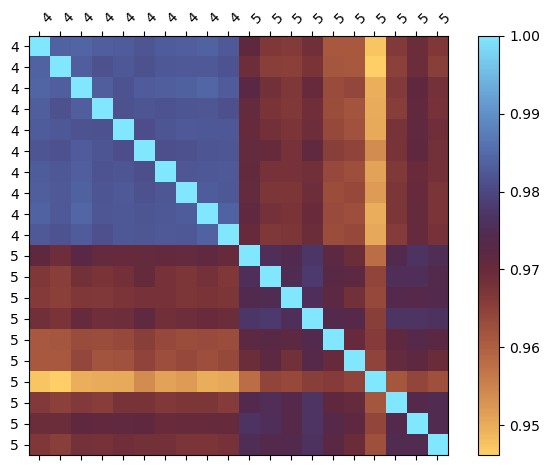

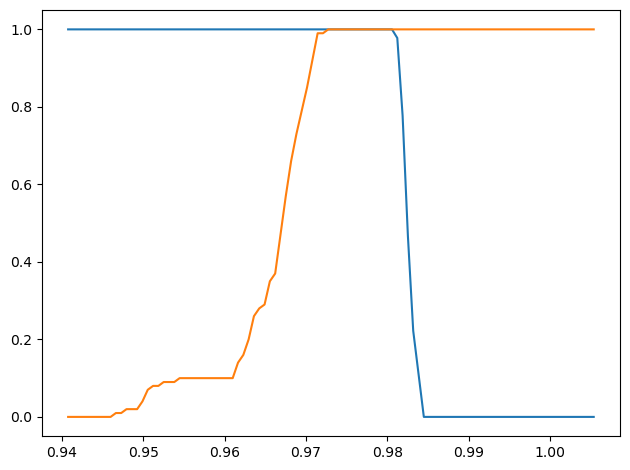

In [37]:
# Mesh 5 heated up to 60 ~ 70 Celsius
group_baseline = [value for value in data['M-SP-PITCH-V2-0004-0.3'] if value['info']['meta'] == 'hot-mesh-hot-serial-5-25-07-02-01-p0.3'][:10]
group_touch = [value for value in data['M-SP-PITCH-V2-0005-0.3'] if value['info']['meta'] == 'hot-mesh-hot-serial-5-25-07-02-01-p0.3'][:10]

smooth = None
plot_vector_covar(group_baseline, group_touch, vector_method='norm', distance_method='corr', smooth=smooth, plot_cdf=True)

2025-07-02T14:12:06.264Z
2025-07-02T16:44:21.617Z
Baseline threshold set at 0.979363
Within class: 0.979±0.00174 min: 0.975 max: 0.983
Cross class: 0.98±0.00134 min: 0.976 max: 0.983
Baseline false negative probability: 0.599033216599
Baseline false positive probability: 0.627495097441


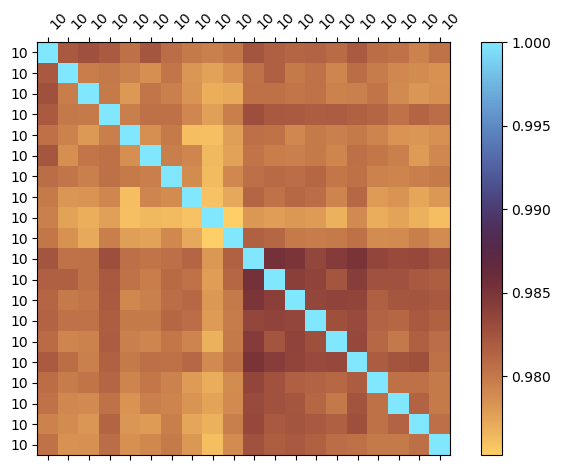

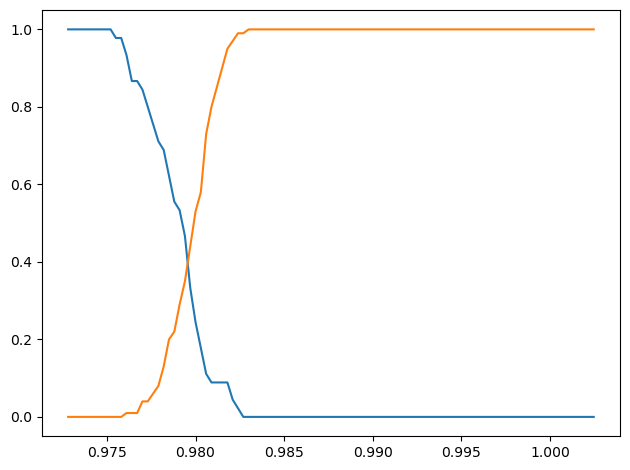

In [38]:
# Compare measurements taken several hours apart, with the board running and measuring a mesh the whole time in between.

group_a = [value for value in data['M-SP-PITCH-V2-0010-0.3'] if value['info']['meta'] == 'probe-interleave-25-07-02-01-p0.3'][:10]
group_b = [value for entry in data.values() for value in entry if value['info']['meta'] == 'baseline-repeat-25-07-02-02-p0.3']
print(group_a[-1]['info']['timestamp'])
print(group_b[-1]['info']['timestamp'])
plot_vector_covar(group_a, group_b, vector_method='norm', distance_method='corr', plot_cdf=True)